In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


In [3]:
# Define transformations
transform = transforms.Compose([
    transforms.ToTensor(),
    # Normalize to [-1, 1] to match Tanh output range
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Load CIFAR-10 training and test datasets
train_dataset = datasets.CIFAR10(root=r'C:\Users\Student\Documents\cifar10_data', train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root=r'C:\Users\Student\Documents\cifar10_data', train=False, download=False, transform=transform)

# Create data loaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of test samples: {len(test_dataset)}")

100%|██████████| 170M/170M [00:11<00:00, 14.7MB/s]


Number of training samples: 50000
Number of test samples: 10000


In [4]:
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super(ConvAutoencoder, self).__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 8, 3, padding=1), # Output: 8x32x32
            nn.ReLU(),
            nn.MaxPool2d(2, 2)            # Output: 8x16x16 (Latent space)
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(8, 3, 2, stride=2), # Output: 3x32x32
            nn.Tanh() # Output pixel values between -1 and 1
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

# Instantiate the model
model = ConvAutoencoder().to(device)
print(model)

ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(8, 3, kernel_size=(2, 2), stride=(2, 2))
    (1): Tanh()
  )
)


In [5]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Loss function: Mean Squared Error")
print("Optimizer: Adam with learning rate 0.001")

Loss function: Mean Squared Error
Optimizer: Adam with learning rate 0.001


In [7]:
num_epochs = 2

for epoch in range(num_epochs):
    running_loss = 0.0
    for data in train_loader:
        inputs, _ = data  # We only need the images, not the labels
        inputs = inputs.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, inputs)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_dataset)
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}')

print('Finished Training')

Epoch [1/2], Loss: 0.0179
Epoch [2/2], Loss: 0.0128
Finished Training


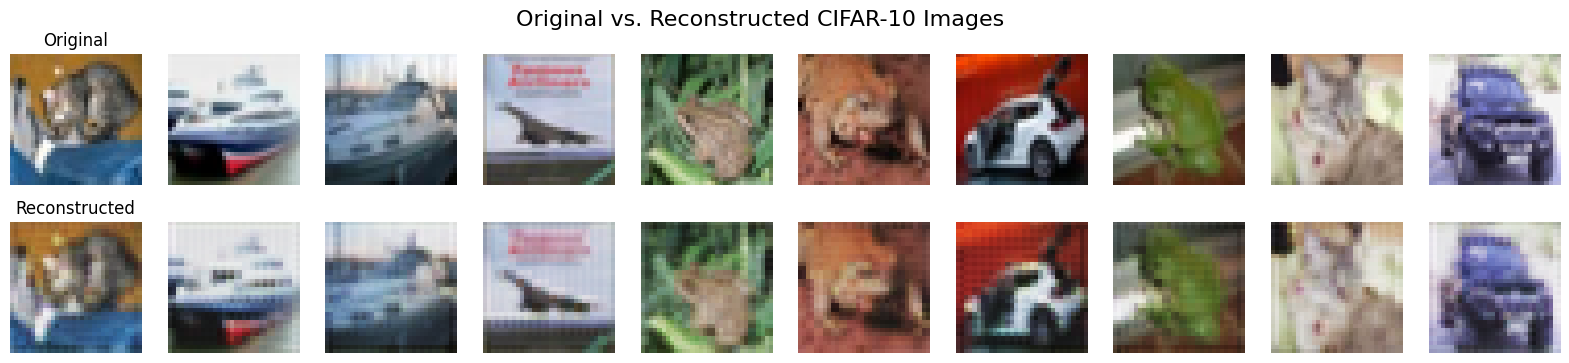

In [8]:
def imshow(img):
    # Unnormalize image for display (undoes the 0.5, 0.5, 0.5 normalization)
    img = img * 0.5 + 0.5 # [-1, 1] -> [0, 1]
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')

# Get a batch of test images
dataiter = iter(test_loader)
images, labels = next(dataiter)

# Pass images through the autoencoder
images = images.to(device)
with torch.no_grad():
    reconstructed_images = model(images)

# Display original and reconstructed images
fig, axes = plt.subplots(nrows=2, ncols=10, figsize=(20, 4))

# Original Images
for i in range(10):
    axes[0, i].imshow(np.transpose(images[i].cpu().numpy() * 0.5 + 0.5, (1, 2, 0)))
    axes[0, i].axis('off')
axes[0, 0].set_title('Original')

# Reconstructed Images
for i in range(10):
    axes[1, i].imshow(np.transpose(reconstructed_images[i].cpu().numpy() * 0.5 + 0.5, (1, 2, 0)))
    axes[1, i].axis('off')
axes[1, 0].set_title('Reconstructed')

plt.suptitle('Original vs. Reconstructed CIFAR-10 Images', fontsize=16)
plt.show()